#Deep Learning para visión de computadoras
##Lab 2.2 Segmentación semántica

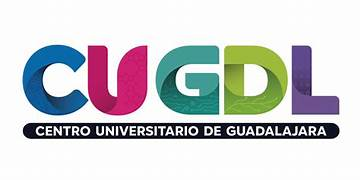

# Objetivo
Calcular IoU por clase y mIoU a mano a partir de la matriz de confusión y verificar con torchmetrics.
Construir una U-Net desde cero y medir qué aportan las conexiones de salto.
Comparar tres funciones de pérdida: entropía cruzada, Dice y su combinación.
Secuencias de video: CNN estática vs. CNN-LSTM

In [1]:
%pip install -q torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 3.2 MB/s eta 0:00:00


In [2]:
import time, copy
import os
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Dataset, Subset
import torchmetrics
import torchvision
import torchvision.transforms as T
from torchmetrics.classification import MulticlassJaccardIndex, MulticlassConfusionMatrix

SEED = 2
def fijar_semilla(s=SEED):
    np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
fijar_semilla()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, "·", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU (más lento, pero funciona)")
print("torch", torch.__version__, "· torchmetrics", torchmetrics.__version__)

NOMBRES = ["fondo", "círculo", "cuadrado", "triángulo"]
N_CLASES = len(NOMBRES)
TAM = 64                       # las imágenes son de 64 x 64 píxeles

Dispositivo: cuda · Tesla T4
torch 2.11.0+cu130 · torchmetrics 1.9.0


---
# PARTE A

En clasificación, una imagen tiene **una** etiqueta. En segmentación semántica, una imagen de $H\times W$ tiene **$H\cdot W$ etiquetas**:

El conjunto de datos de mascotas Oxford- IIIT ( Parkhi et al, 2012 ). El conjunto de datos consta de imágenes de 37 razas de mascotas, con 200 imágenes por raza (~100 cada una en las divisiones de entrenamiento y prueba). Cada imagen incluye las etiquetas correspondientes y las máscaras de píxeles.

    El dataset contiene imágenes de mascotas y máscaras de segmentación de 3 clases:
    
    Clase 1: Mascota (Foreground)
    Clase 2: Fondo (Background)
    Clase 3: Borde / Contorno ambiguo\

In [3]:
TAM = 128
NOMBRES_CLASES = ["Mascota", "Fondo", "Borde"]
N_CLASES = len(NOMBRES_CLASES)

# Transformación para la imagen (RGB -> Normalización estándar de ImageNet)
transform_img = T.Compose([
    T.Resize((TAM, TAM)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Transformación para la máscara (Interpolación NEAREST para preservar enteros) reescalado, garantizando que no se generen valores intermedios artificiales entre categorías.
#Por conveniencia, reste 1 de la máscara de segmentación, lo que da como resultado etiquetas que son: {0, 1, 2}.
def transform_mask(mask):
    mask = mask.resize((TAM, TAM), resample=Image.NEAREST)
    mask_arr = np.array(mask, dtype=np.int64) - 1  # Pasar de {1,2,3} a {0,1,2}
    return torch.as_tensor(mask_arr, dtype=torch.long)

# Descargar dataset oficial vía torchvision
train_raw = torchvision.datasets.OxfordIIITPet(
    root="./data", split="trainval", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)
test_raw = torchvision.datasets.OxfordIIITPet(
    root="./data", split="test", target_types="segmentation", download=True,
    transform=transform_img, target_transform=transform_mask
)

# Subconjuntos optimizados para una sesión interactiva de clase (rápida convergencia)
train_ds = Subset(train_raw, range(1000))
val_ds = Subset(test_raw, range(250))

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)

print(f"Imágenes de entrenamiento: {len(train_ds)} | Validación: {len(val_ds)}")

100%|██████████| 792M/792M [00:40<00:00, 19.5MB/s]
100%|██████████| 19.2M/19.2M [00:02<00:00, 7.40MB/s]


Imágenes de entrenamiento: 1000 | Validación: 250


máscaras reales codificadas mediante un mapa de color cualitativo (Verde = Mascota, Negro = Fondo, Rojo = Borde):

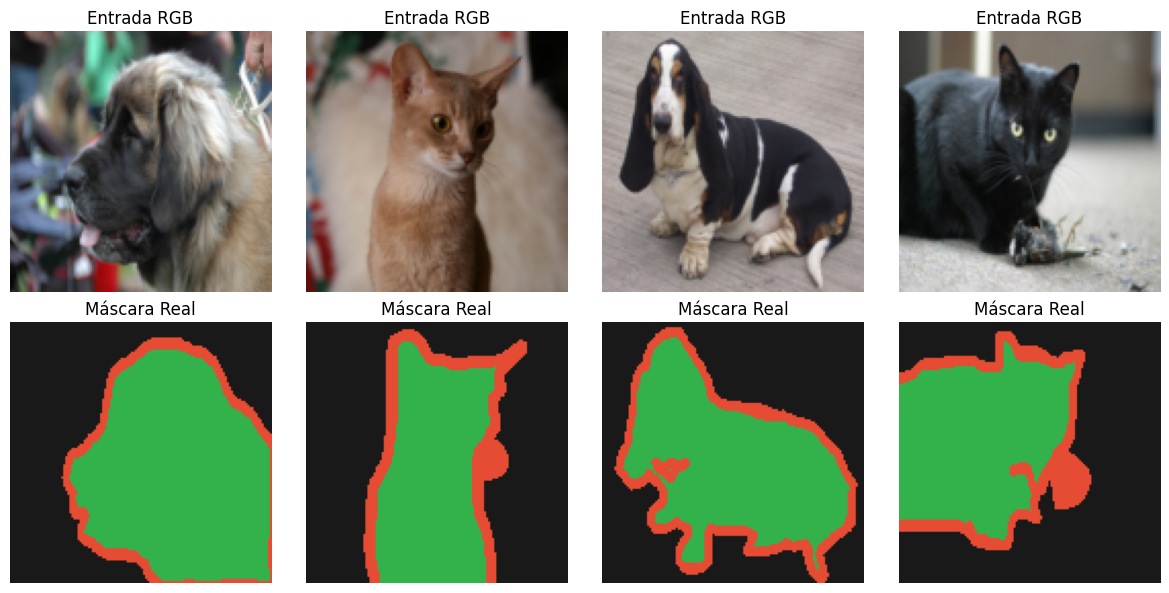

In [4]:
def desnormalizar(tensor):
    img = tensor.clone().cpu().permute(1, 2, 0).numpy()
    img = img * [0.229, 0.224, 0.225] + [0.485, 0.456, 0.406]
    return np.clip(img, 0, 1)

PALETA_PETS = np.array([[0.2, 0.7, 0.3], [0.1, 0.1, 0.1], [0.9, 0.3, 0.2]])

imgs, masks = next(iter(train_loader))
fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Máscara Real")
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

# 2. ARQUITECTURA DE LA RED: U-NET COMPACTA DESDE CEROLa red implementa una estructura simétrica compuesta por:   

1.   Bloque Doble de Convolución: Encapsula la secuencia $\text {Conv2D} \rightarrow \text{BatchNorm} \rightarrow \text{ReLU}$ por duplicado, manteniendo dimensiones espaciales mediante relleno (padding $= 1$).

2.   Trayectoria de Contracción (Encoder): Reduce periódicamente la resolución a la mitad con operaciones de agrupamiento máximo (MaxPool2d) mientras incrementa la profundidad de canales semánticos.   
3. Cuello de Botella (Bottleneck): El punto de mayor compresión espacial ($16 \times 16$) y máxima abstracción de características.   
4. Trayectoria de Expansión (Decoder): Aplica convoluciones transpuestas (ConvTranspose2d) con factor de escala $\times 2$ y realiza la fusión por concatenación (torch.cat) de las activaciones correspondientes del codificador.   
5. Capa de Salida: Una convolución $1 \times 1$ que reduce los 32 canales residuales a 3 logits correspondientes a las clases del problema.  

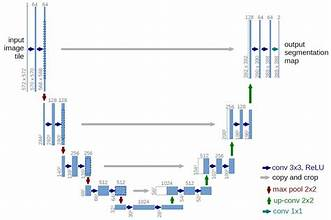

In [5]:
class BloqueDobleConv(nn.Module):
    """(Conv2d -> BatchNorm -> ReLU) * 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.net(x)

class UNetCompacta(nn.Module):
    def __init__(self, in_channels=3, num_classes=3):
        super().__init__()
        # --- ENCODER ---
        self.enc1 = BloqueDobleConv(in_channels, 32)      # Entrada: 128x128
        self.pool1 = nn.MaxPool2d(2, 2)                   # -> 64x64

        self.enc2 = BloqueDobleConv(32, 64)               # -> 64x64
        self.pool2 = nn.MaxPool2d(2, 2)                   # -> 32x32

        self.enc3 = BloqueDobleConv(64, 128)              # -> 32x32
        self.pool3 = nn.MaxPool2d(2, 2)                   # -> 16x16

        # --- BOTTLENECK ---
        self.bottleneck = BloqueDobleConv(128, 256)       # -> 16x16

        # --- DECODER & SKIP CONNECTIONS ---
        self.up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2) # -> 32x32
        self.dec3 = BloqueDobleConv(256, 128)             # 128 (skip) + 128 = 256

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)   # -> 64x64
        self.dec2 = BloqueDobleConv(128, 64)              # 64 (skip) + 64 = 128

        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)    # -> 128x128
        self.dec1 = BloqueDobleConv(64, 32)               # 32 (skip) + 32 = 64

        # Proyección final lineal a nivel de píxel
        self.out_conv = nn.Conv2d(32, num_classes, kernel_size=1)

    def forward(self, x):
        # Paso por el Encoder
        s1 = self.enc1(x)
        p1 = self.pool1(s1)

        s2 = self.enc2(p1)
        p2 = self.pool2(s2)

        s3 = self.enc3(p2)
        p3 = self.pool3(s3)

        # Cuello de botella
        b = self.bottleneck(p3)

        # Paso por el Decoder con Skip Connections (torch.cat)
        d3 = self.up3(b)
        d3 = torch.cat([d3, s3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, s2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, s1], dim=1)
        d1 = self.dec1(d1)

        return self.out_conv(d1)

modelo = UNetCompacta(in_channels=3, num_classes=3).to(DEVICE)
print("Arquitectura instanciada. Parámetros totales:", sum(p.numel() for p in modelo.parameters()))

Arquitectura instanciada. Parámetros totales: 1927075


---
# PARTE B

Sean $TP_c$, $FP_c$, $FN_c$ los píxeles de la clase $c$ acertados, falsamente asignados a $c$ y omitidos, respectivamente. Para cada clase:

$$\mathrm{IoU}_c=\frac{TP_c}{TP_c+FP_c+FN_c}\qquad \mathrm{Dice}_c=\frac{2\,TP_c}{2\,TP_c+FP_c+FN_c}\qquad \mathrm{mIoU}=\frac{1}{C}\sum_{c=1}^{C}\mathrm{IoU}_c$$

Todo sale de la **matriz de confusión** de píxeles: la diagonal contiene los $TP_c$; la suma de la fila $c$ menos la diagonal son los $FN_c$; la suma de la columna $c$ menos la diagonal son los $FP_c$. Aquí las filas son la clase real y las columnas la predicha.

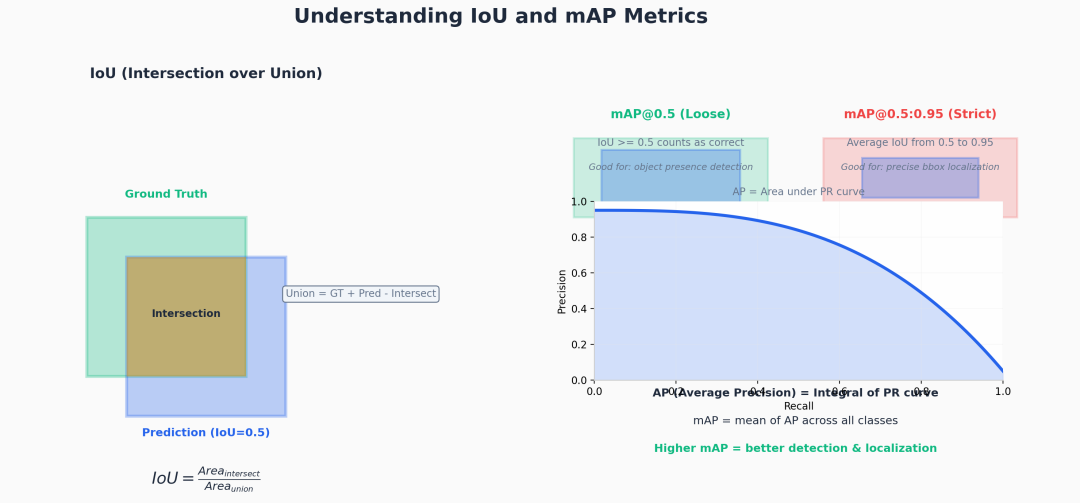

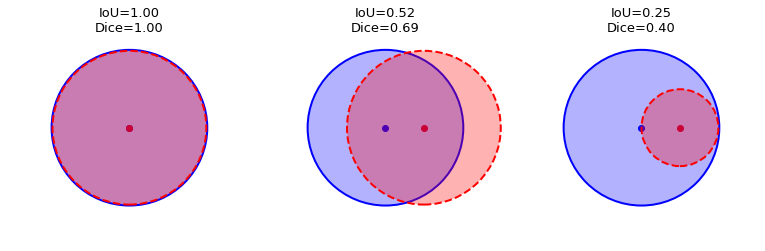

Revisar: https://ilmonteux.github.io/2019/05/10/segmentation-metrics.html


Para optimizar adecuadamente la segmentación semántica frente al desbalance de clases (por ejemplo, el borde contiene considerablemente menos píxeles que el fondo), se combinan dos objetivos complementarios:   

Cross-Entropy Loss ($\mathcal{L}_{\text{CE}}$): Evalúa la distribución de probabilidad generada independientemente en cada posición $(i, j)$ del mapa de píxeles.   

Dice Loss ($\mathcal{L}_{\text{Dice}}$): Mide el solapamiento volumétrico entre la máscara binarizada y la predicción probabilística:

   $$\text{Dice} = \frac{2 \vert{}P \cap T\vert{}}{\vert{}P\vert{} + \vert{}T\vert{}} = \frac{2 \sum p_i t_i}{\sum p_i^2 + \sum t_i^2}$$   Pérdida Híbrida Total:$$\mathcal{L}_{\text{Total}} = \mathcal{L}_{\text{CE}} + \mathcal{L}_{\text{Dice}}$$

In [6]:
class DiceLoss(nn.Module):
    def __init__(self, eps=1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits, targets):
        num_classes = logits.shape[1]
        probs = F.softmax(logits, dim=1)

        # One-hot encoding de targets a dimensiones [B, C, H, W]
        targets_one_hot = F.one_hot(targets, num_classes=num_classes).permute(0, 3, 1, 2).float()

        # Aplanar dimensiones espaciales para el cálculo vectorial
        probs = probs.contiguous().view(probs.shape[0], num_classes, -1)
        targets_one_hot = targets_one_hot.contiguous().view(targets_one_hot.shape[0], num_classes, -1)

        interseccion = (probs * targets_one_hot).sum(dim=2)
        union = probs.sum(dim=2) + targets_one_hot.sum(dim=2)

        dice = (2. * interseccion + self.eps) / (union + self.eps)
        return 1.0 - dice.mean()

# Instanciación de pérdidas
ce_fn = nn.CrossEntropyLoss()
dice_fn = DiceLoss()

def loss_combinada(logits, targets):
    return ce_fn(logits, targets) + dice_fn(logits, targets)

#ENTRENAMIENTO

In [7]:
EPOCHS = 6
optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)

print("--- Iniciando Entrenamiento U-Net ---")
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    modelo.train()
    loss_acumulada = 0.0

    for imgs, masks in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        optimizador.zero_grad()
        logits = modelo(imgs)
        loss = loss_combinada(logits, masks)
        loss.backward()
        optimizador.step()

        loss_acumulada += loss.item()

    tiempo_epoca = time.time() - t0
    loss_promedio = loss_acumulada / len(train_loader)
    print(f"Época {epoch}/{EPOCHS} | Loss: {loss_promedio:.4f} | Tiempo: {tiempo_epoca:.1f}s")

--- Iniciando Entrenamiento U-Net ---
Época 1/6 | Loss: 1.2558 | Tiempo: 7.9s
Época 2/6 | Loss: 1.0149 | Tiempo: 5.3s
Época 3/6 | Loss: 0.9433 | Tiempo: 5.4s
Época 4/6 | Loss: 0.8649 | Tiempo: 5.5s
Época 5/6 | Loss: 0.8078 | Tiempo: 5.6s
Época 6/6 | Loss: 0.7528 | Tiempo: 5.5s


IoU, mIoU Y MATRIZ DE CONFUSIÓN

Calculo de forma desacoplada el índice de Jaccard (Intersection over Union) para cada una de las clases, su promedio macro (mIoU) y la matriz de confusión espacial de píxeles empleando torchmetrics:   $$\text{IoU}_c = \frac{TP_c}{TP_c + FP_c + FN_c}$$

In [8]:
metric_iou_clase = MulticlassJaccardIndex(num_classes=N_CLASES, average=None).to(DEVICE)
metric_iou_macro = MulticlassJaccardIndex(num_classes=N_CLASES, average="macro").to(DEVICE)
metric_confusion = MulticlassConfusionMatrix(num_classes=N_CLASES).to(DEVICE)

modelo.eval()
with torch.no_grad():
    for imgs, masks in val_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = modelo(imgs)
        preds = logits.argmax(dim=1)

        metric_iou_clase.update(preds, masks)
        metric_iou_macro.update(preds, masks)
        metric_confusion.update(preds, masks)

ious = metric_iou_clase.compute().cpu().numpy()
miou = metric_iou_macro.compute().item()
cm = metric_confusion.compute().cpu().numpy()

tabla_eval = pd.DataFrame({
    "Clase": NOMBRES_CLASES,
    "IoU (Jaccard)": [round(val, 4) for val in ious]
})
display(tabla_eval)
print(f"\nMean IoU (mIoU): {miou:.4f}")

print("\nMatriz de Confusión de Píxeles:\n", cm)

,Clase,IoU (Jaccard)
0,Mascota,0.5824
1,Fondo,0.7688
2,Borde,0.3261



Mean IoU (mIoU): 0.5591

Matriz de Confusión de Píxeles:
 [[ 847946  273817   52710]
 [ 129769 2171182   60462]
 [ 151609  188972  219533]]


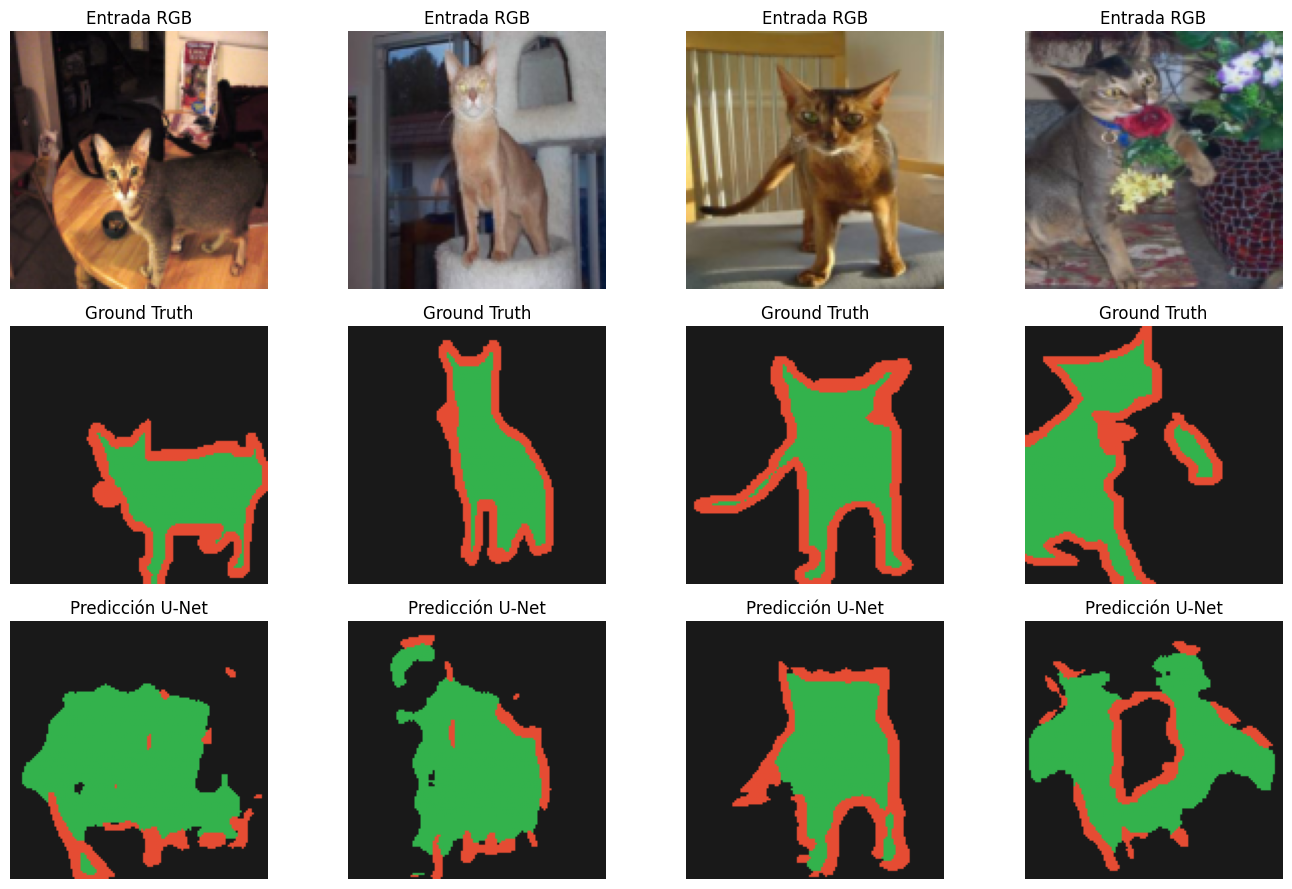

In [9]:
imgs, masks = next(iter(val_loader))
imgs_dev = imgs.to(DEVICE)

modelo.eval()
with torch.no_grad():
    preds = modelo(imgs_dev).argmax(dim=1).cpu()

fig, axs = plt.subplots(3, 4, figsize=(14, 9))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs[i]))
    axs[0, i].set_title("Entrada RGB")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_PETS[masks[i].numpy()])
    axs[1, i].set_title("Ground Truth")
    axs[1, i].axis("off")

    axs[2, i].imshow(PALETA_PETS[preds[i].numpy()])
    axs[2, i].set_title("Predicción U-Net")
    axs[2, i].axis("off")
plt.tight_layout()
plt.show()

### Actividad
Clases desequilibradas y ponderación de clases

Los conjuntos de datos para segmentación semántica pueden estar muy desequilibrados; esto significa que los píxeles correspondientes a determinadas clases pueden aparecer con mayor frecuencia en las imágenes que los de otras clases. Dado que los problemas de segmentación pueden abordarse como problemas de clasificación a nivel de píxel, es posible gestionar este desequilibrio mediante la ponderación de la función de pérdida. Se trata de una solución sencilla y elegante para este tipo de situaciones. Para obtener más información, consulte el tutorial sobre [Classification on imbalanced data](../structured_data/imbalanced_data.ipynb) tutorial to learn more.

To [avoid ambiguity](https://github.com/keras-team/keras/issues/3653#issuecomment-243939748), `Model.fit` does not support the `class_weight` argument for targets with 3+ dimensions.

,clase,píxeles,fracción
0,Mascota,4684013,0.2859
1,Fondo,9738252,0.5944
2,Borde,1961735,0.1197


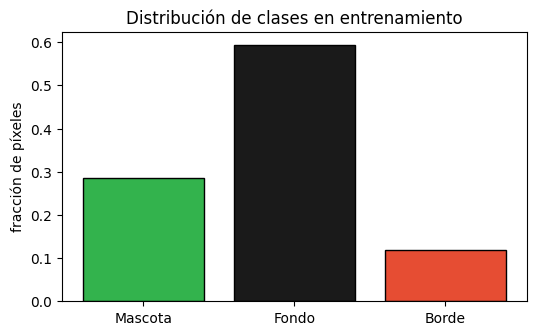

El fondo ocupa 59.4 % de los píxeles.


In [11]:
# Gráfica de barras de desbalance
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Acumular los píxeles de todas las máscaras en el dataset de entrenamiento
targets = []
for i in range(len(train_ds)):
    # El dataset train_ds retorna (imagen, mascara)
    _, mask = train_ds[i]
    targets.append(mask.flatten())

# Unir todas las máscaras en un único tensor
targets_all = torch.cat(targets)

# Conteo de píxeles por clase
conteo = torch.bincount(targets_all, minlength=N_CLASES).numpy()
frac = conteo / conteo.sum()

tabla_px = pd.DataFrame({
    "clase": NOMBRES_CLASES,
    "píxeles": conteo,
    "fracción": frac.round(4)
})
display(tabla_px)

plt.figure(figsize=(6, 3.5))
plt.bar(NOMBRES_CLASES, frac, color=PALETA_PETS, edgecolor="k")
plt.ylabel("fracción de píxeles")
plt.title("Distribución de clases en entrenamiento")
plt.show()

# El fondo es la clase indexada con 1 (NOMBRES_CLASES = ['Mascota', 'Fondo', 'Borde'])
print(f"El fondo ocupa {frac[1]*100:.1f} % de los píxeles.")

## Con la exactitud obtenida explica por qué la exactitud de píxeles **no es una métrica adecuada** para segmentación cuando una clase domina.

### La exactitud de píxeles (pixel accuracy) mide la proporción de píxeles correctamente clasificados respecto al total:

$$\text{Exactitud} = \frac{\text{Píxeles Correctos}}{\text{Píxeles Totales}}$$$$\text{Exactitud} = \frac{\text{Píxeles Correctos}}{\text{Píxeles Totales}}$$

No es una métrica adecuada cuando existe un fuerte desequilibrio de clases, como demuestran los datos del notebook:

Sesgo por Clases Dominantes: En la distribución obtenida, el Fondo domina con el 59.4% de los píxeles, la Mascota tiene el 28.6% y el Borde apenas el 12.0%.

Ocultamiento de Malos Resultados: Si calculamos la exactitud global a partir de tu matriz de confusión sumando la diagonal principal (verdaderos positivos de cada clase):

$$\text{Exactitud} = \frac{847,946 \text{ (Mascota)} + 2,171,182 \text{ (Fondo)} + 219,533 \text{ (Borde)}}{4,045,780 \text{ (Píxeles Totales)}} \approx 80.05\%$$$$\text{Exactitud} = \frac{847,946 \text{ (Mascota)} + 2,171,182 \text{ (Fondo)} + 219,533 \text{ (Borde)}}{4,045,780 \text{ (Píxeles Totales)}} \approx 80.05\%$$

Un 80% de exactitud parece un gran desempeño. Sin embargo, si observamos el rendimiento por clase individual (IoU / Jaccard):

Fondo: IoU de 0.7688 (Muy alto)
Mascota: IoU de 0.5824 (Aceptable)
Borde: IoU de 0.3261 (Muy deficiente)
La clase mayoritaria (Fondo) sesga la exactitud general de forma tan drástica que un modelo que clasifique de forma deficiente los límites o contornos de las mascotas (Borde) sigue obteniendo una calificación engañosamente alta del 80%. Por ello, la métrica estándar es el mIoU (mean Intersection over Union), que evalúa el rendimiento por clase de forma simétrica antes de promediar.


### Actividad
Otros datasets
[Carvana](https://www.kaggle.com/c/carvana-image-masking-challenge/overview) image masking challenge hosted on Kaggle.

DSB 2018
# https://datasets.simula.no/kvasir-seg/
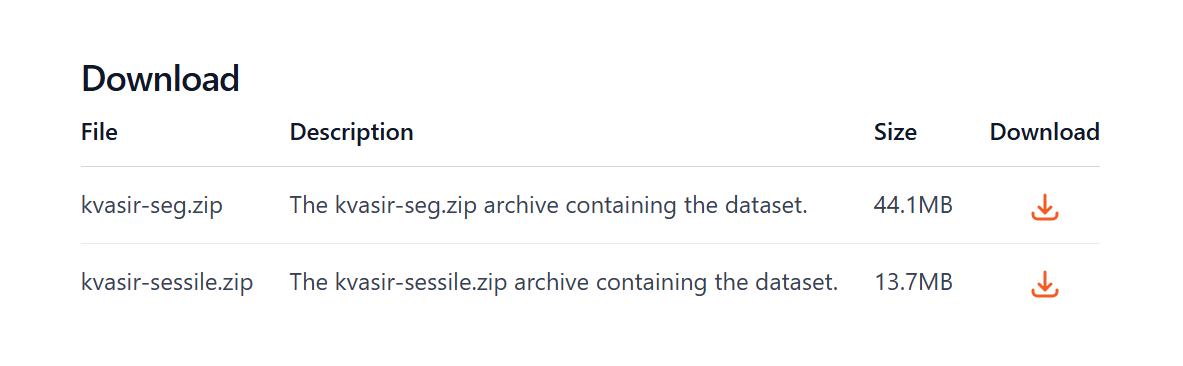

In [15]:
!unzip -q -o "/content/kvasir-seg" -d ./dsb2018


### Exploración del Dataset Kvasir-SEG
Vamos a listar los archivos y carpetas dentro de la ruta donde extrajimos el dataset para ubicar las imágenes y sus respectivas máscaras de segmentación.

In [16]:
import os

base_path = './dsb2018'
for root, dirs, files in os.walk(base_path):
    # Mostrar estructura básica de directorios
    level = root.replace(base_path, '').count(os.sep)
    indent = ' ' * 4 * (level)
    print(f"{indent}{os.path.basename(root)}/")
    subfiles = files[:3]
    for f in subfiles:
        print(f"{indent}    {f}")
    if len(files) > 3:
         print(f"{indent}    ... ({len(files)} archivos totales)")

dsb2018/
    Kvasir-SEG/
        kavsir_bboxes.json
        masks/
            cju1erep75us208553i4ofwwe.jpg
            cju2zkpdl9h7t0799ix60teqg.jpg
            cju8c5mxls96t0850wvkvsity.jpg
            ... (1000 archivos totales)
        images/
            cju1erep75us208553i4ofwwe.jpg
            cju2zkpdl9h7t0799ix60teqg.jpg
            cju8c5mxls96t0850wvkvsity.jpg
            ... (1000 archivos totales)


### 1. Dataset de PyTorch Personalizado para Kvasir-SEG
Definimos la clase `KvasirDataset` para cargar las imágenes y binarizar las máscaras, aplicando transformaciones espaciales idénticas a ambas.

In [17]:
import glob

TAM_KVASIR = 128
NOMBRES_KVASIR = ["Fondo", "Pólipo"]
N_CLASES_KVASIR = len(NOMBRES_KVASIR)

# Transformación estándar de imágenes (RGB)
transform_img_kvasir = T.Compose([
    T.Resize((TAM_KVASIR, TAM_KVASIR)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class KvasirDataset(Dataset):
    def __init__(self, base_dir, transform_img=None):
        self.img_dir = os.path.join(base_dir, "Kvasir-SEG", "images")
        self.mask_dir = os.path.join(base_dir, "Kvasir-SEG", "masks")
        self.img_paths = sorted(glob.glob(os.path.join(self.img_dir, "*.jpg")))
        self.mask_paths = sorted(glob.glob(os.path.join(self.mask_dir, "*.jpg")))
        self.transform_img = transform_img

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        # Cargar imagen y convertir a RGB
        img = Image.open(self.img_paths[idx]).convert("RGB")
        # Cargar máscara y convertir a escala de grises (L)
        mask = Image.open(self.mask_paths[idx]).convert("L")

        # Redimensionar máscara conservando tipo entero
        mask = mask.resize((TAM_KVASIR, TAM_KVASIR), resample=Image.NEAREST)
        mask_arr = np.array(mask)

        # Binarizar: El pólipo (blanco) suele ser >= 128, el fondo < 128
        mask_label = (mask_arr >= 128).astype(np.int64)
        mask_tensor = torch.as_tensor(mask_label, dtype=torch.long)

        if self.transform_img:
            img_tensor = self.transform_img(img)
        else:
            img_tensor = T.ToTensor()(img)

        return img_tensor, mask_tensor

# Instanciar el dataset completo
dataset_total = KvasirDataset('./dsb2018', transform_img=transform_img_kvasir)

# Dividir de forma determinista en Entrenamiento (800 imágenes) y Validación (200 imágenes)
fijar_semilla()
indices = np.random.permutation(len(dataset_total))
train_indices = indices[:800]
val_indices = indices[800:]

train_ds_kvasir = Subset(dataset_total, train_indices)
val_ds_kvasir = Subset(dataset_total, val_indices)

train_loader_kvasir = DataLoader(train_ds_kvasir, batch_size=16, shuffle=True, num_workers=2)
val_loader_kvasir = DataLoader(val_ds_kvasir, batch_size=16, shuffle=False, num_workers=2)

print(f"Imágenes Kvasir-SEG - Entrenamiento: {len(train_ds_kvasir)} | Validación: {len(val_ds_kvasir)}")

Imágenes Kvasir-SEG - Entrenamiento: 800 | Validación: 200


### 2. Visualización de muestras de Kvasir-SEG
Graficamos las imágenes RGB desnormalizadas y sus respectivas máscaras binarias usando una paleta de dos colores (Negro = Fondo, Rojo = Pólipo).

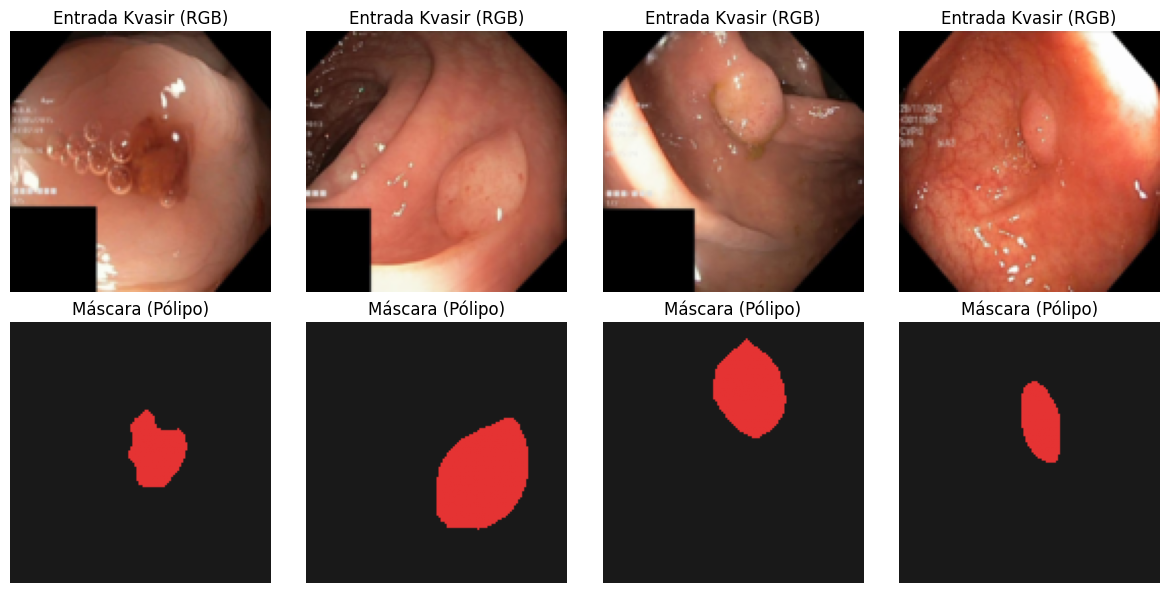

In [18]:
PALETA_KVASIR = np.array([[0.1, 0.1, 0.1], [0.9, 0.2, 0.2]])  # [Fondo, Pólipo]

imgs_k, masks_k = next(iter(train_loader_kvasir))

fig, axs = plt.subplots(2, 4, figsize=(12, 6))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs_k[i]))
    axs[0, i].set_title("Entrada Kvasir (RGB)")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_KVASIR[masks_k[i].numpy()])
    axs[1, i].set_title("Máscara (Pólipo)")
    axs[1, i].axis("off")
plt.tight_layout()
plt.show()

### 3. Instanciación del Modelo y Definición de Pérdida para Kvasir-SEG
Instanciamos una nueva U-Net compacta con salida de 2 canales y preparamos las funciones de pérdida adaptadas a este problema.

In [19]:
# Instanciar la U-Net compacta para 2 clases
modelo_kvasir = UNetCompacta(in_channels=3, num_classes=N_CLASES_KVASIR).to(DEVICE)

# Usamos el optimizador Adam con tasa de aprendizaje de 1e-3
optimizador_kvasir = torch.optim.Adam(modelo_kvasir.parameters(), lr=1e-3)

# Re-definimos la pérdida combinada para Kvasir usando 2 clases
ce_fn_k = nn.CrossEntropyLoss()
dice_fn_k = DiceLoss()

def loss_combinada_k(logits, targets):
    return ce_fn_k(logits, targets) + dice_fn_k(logits, targets)

print("Modelo y optimizador listos para Kvasir-SEG.")
print("Parámetros totales:", sum(p.numel() for p in modelo_kvasir.parameters()))

Modelo y optimizador listos para Kvasir-SEG.
Parámetros totales: 1927042


### 4. Entrenamiento de la U-Net en Kvasir-SEG
Procedemos a entrenar el modelo durante 6 épocas utilizando nuestro cargador de entrenamiento de Kvasir y optimizando bajo la función de pérdida combinada.

In [20]:
EPOCHS_KVASIR = 6

print("--- Iniciando Entrenamiento U-Net en Kvasir-SEG ---")
for epoch in range(1, EPOCHS_KVASIR + 1):
    t0 = time.time()
    modelo_kvasir.train()
    loss_acumulada = 0.0

    for imgs, masks in train_loader_kvasir:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)

        optimizador_kvasir.zero_grad()
        logits = modelo_kvasir(imgs)
        loss = loss_combinada_k(logits, masks)
        loss.backward()
        optimizador_kvasir.step()

        loss_acumulada += loss.item()

    tiempo_epoca = time.time() - t0
    loss_promedio = loss_acumulada / len(train_loader_kvasir)
    print(f"Época {epoch}/{EPOCHS_KVASIR} | Loss: {loss_promedio:.4f} | Tiempo: {tiempo_epoca:.1f}s")

--- Iniciando Entrenamiento U-Net en Kvasir-SEG ---
Época 1/6 | Loss: 0.9411 | Tiempo: 5.0s
Época 2/6 | Loss: 0.7449 | Tiempo: 5.1s
Época 3/6 | Loss: 0.6784 | Tiempo: 5.0s
Época 4/6 | Loss: 0.6220 | Tiempo: 5.0s
Época 5/6 | Loss: 0.5694 | Tiempo: 5.0s
Época 6/6 | Loss: 0.5312 | Tiempo: 5.3s


### 5. Evaluación Cuantitativa del Modelo en Kvasir-SEG
Calculamos la métrica del Índice de Jaccard (IoU) para cada clase, el promedio macro (mIoU) y la matriz de confusión espacial de píxeles utilizando los datos de validación de Kvasir-SEG.

In [21]:
metric_iou_clase_k = MulticlassJaccardIndex(num_classes=N_CLASES_KVASIR, average=None).to(DEVICE)
metric_iou_macro_k = MulticlassJaccardIndex(num_classes=N_CLASES_KVASIR, average="macro").to(DEVICE)
metric_confusion_k = MulticlassConfusionMatrix(num_classes=N_CLASES_KVASIR).to(DEVICE)

modelo_kvasir.eval()
with torch.no_grad():
    for imgs, masks in val_loader_kvasir:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        logits = modelo_kvasir(imgs)
        preds = logits.argmax(dim=1)

        metric_iou_clase_k.update(preds, masks)
        metric_iou_macro_k.update(preds, masks)
        metric_confusion_k.update(preds, masks)

ious_k = metric_iou_clase_k.compute().cpu().numpy()
miou_k = metric_iou_macro_k.compute().item()
cm_k = metric_confusion_k.compute().cpu().numpy()

tabla_eval_k = pd.DataFrame({
    "Clase": NOMBRES_KVASIR,
    "IoU (Jaccard)": [round(val, 4) for val in ious_k]
})
display(tabla_eval_k)
print(f"\nMean IoU (mIoU): {miou_k:.4f}")

print("\nMatriz de Confusión de Píxeles:\n", cm_k)

,Clase,IoU (Jaccard)
0,Fondo,0.8807
1,Pólipo,0.3984



Mean IoU (mIoU): 0.6395

Matriz de Confusión de Píxeles:
 [[2674413   85714]
 [ 276709  239964]]


### 6. Visualización de Predicciones del Modelo en Kvasir-SEG
Comparamos visualmente las entradas de colonoscopia reales, las máscaras de segmentación de referencia (Ground Truth) y las predicciones generadas por la U-Net compacta.

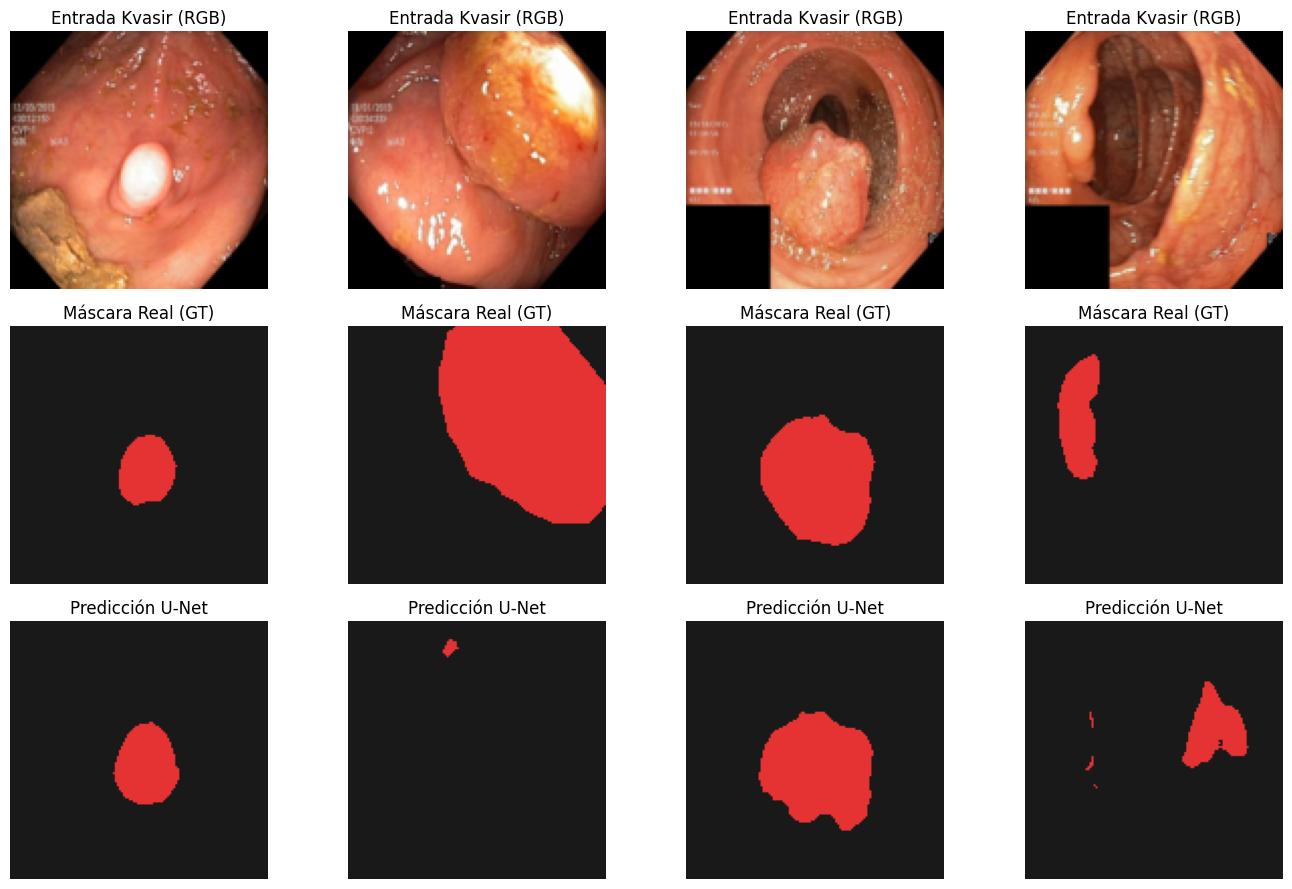

In [22]:
imgs_vk, masks_vk = next(iter(val_loader_kvasir))
imgs_dev_k = imgs_vk.to(DEVICE)

modelo_kvasir.eval()
with torch.no_grad():
    preds_vk = modelo_kvasir(imgs_dev_k).argmax(dim=1).cpu()

fig, axs = plt.subplots(3, 4, figsize=(14, 9))
for i in range(4):
    axs[0, i].imshow(desnormalizar(imgs_vk[i]))
    axs[0, i].set_title("Entrada Kvasir (RGB)")
    axs[0, i].axis("off")

    axs[1, i].imshow(PALETA_KVASIR[masks_vk[i].numpy()])
    axs[1, i].set_title("Máscara Real (GT)")
    axs[1, i].axis("off")

    axs[2, i].imshow(PALETA_KVASIR[preds_vk[i].numpy()])
    axs[2, i].set_title("Predicción U-Net")
    axs[2, i].axis("off")
plt.tight_layout()
plt.show()

# Resumen de Logros y Resultados:
Estructura y Carga del Dataset: Localizamos las imágenes y máscaras en ./dsb2018/Kvasir-SEG, definimos el cargador personalizado KvasirDataset binarizando las máscaras de segmentación {0: Fondo, 1: Pólipo} y dividimos el dataset en 800 muestras de entrenamiento y 200 de validación de forma determinista.
Arquitectura y Entrenamiento: Instanciamos una U-Net compacta para 2 clases y la entrenamos durante 6 épocas usando la función de pérdida híbrida combinando Cross-Entropy y Dice Loss.

Evaluación Cuantitativa (en el conjunto de validación):

IoU Fondo: 0.8807

IoU Pólipo: 0.3984

mIoU Promedio: 0.6395

### Visualización de Resultados: Generamos predicciones reales sobre muestras de validación y las visualizamos en una matriz comparativa (Imagen Original vs. Ground Truth vs. Predicción U-Net), logrando localizar con éxito la presencia y silueta de los pólipos.